<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_1_Intro_to_DS_and_Naive_Bayes/Projects/Instructions/Project.1-Transactions/Project.1-Pass-06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project.1_Pass-06, Transaction Data




## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


### Load Pandas, Numpy, and Matplotlib modules

In [53]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

### Load data Train.csv from AWS S3[link text](https://)

In [54]:
# Load data Train.csv from AWS S3
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'
url

df = pd.read_csv( url )

df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,179995,train_179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,179996,train_179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,179997,train_179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,179998,train_179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760


In [55]:
# Look at the first few rows
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974


In [56]:
# Look at the last few rows
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
179995,179995,train_179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,179996,train_179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,179997,train_179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,179998,train_179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760
179999,179999,train_179999,0,11.6252,3.3959,11.5558,4.2003,7.4666,13.7381,12.9590,...,5.0415,-2.4210,-3.6829,14.2422,1.0741,26.3943,4.1482,11.9539,2.9846,15.6002


In [57]:
# Shape of the dataframe
df.shape

(180000, 53)

In [58]:
# Size of the dataframe
df.size

9540000

### Summary Meta-Data

In [59]:
# Display meta-data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 53 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Unnamed: 0  180000 non-null  int64  
 1   ID_code     180000 non-null  object 
 2   target      180000 non-null  int64  
 3   var_0       180000 non-null  float64
 4   var_1       180000 non-null  float64
 5   var_2       180000 non-null  float64
 6   var_3       180000 non-null  float64
 7   var_4       180000 non-null  float64
 8   var_5       180000 non-null  float64
 9   var_6       180000 non-null  float64
 10  var_7       180000 non-null  float64
 11  var_8       180000 non-null  float64
 12  var_9       180000 non-null  float64
 13  var_10      180000 non-null  float64
 14  var_11      180000 non-null  float64
 15  var_12      180000 non-null  float64
 16  var_13      180000 non-null  float64
 17  var_14      180000 non-null  float64
 18  var_15      180000 non-null  float64
 19  va

### Summary Statistics

In [60]:
# Display summary statistics
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
count,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.00000,180000.000000,...,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000,180000.000000
mean,89999.500000,0.100222,10.678650,-1.630045,10.712922,5.408688,7.566953,14.024017,8.52808,15.243424,...,5.635897,-0.000418,-0.668334,20.208845,2.595090,12.756574,3.236201,7.440715,1.927078,15.870166
std,51961.668564,0.300297,3.041036,4.050519,2.639146,0.866265,1.235043,0.190038,4.64170,7.851050,...,0.369629,4.422915,5.968300,7.132446,2.801692,9.320939,4.561317,3.021636,1.476777,3.010492
min,0.000000,0.000000,0.408400,-15.043400,2.117100,2.347300,3.970500,13.434600,-6.01110,-10.664200,...,4.258800,-14.506000,-22.748700,-2.995300,-7.856100,-18.489700,-14.093300,-2.691700,-3.814500,6.299300
25%,44999.750000,0.000000,8.451675,-4.745600,8.720000,4.768500,6.618800,13.893900,5.06575,9.170200,...,5.374200,-3.253575,-4.997500,15.062900,0.628600,5.661300,-0.062000,5.160325,0.890000,13.830400
50%,89999.500000,0.000000,10.526750,-1.611250,10.579600,5.385600,7.628500,14.025500,8.59920,15.198900,...,5.634500,0.008500,-0.560300,20.203300,2.513800,12.520300,3.204650,7.350950,1.899700,15.934600
75%,134999.250000,0.000000,12.756200,1.360225,12.514100,6.003200,8.583800,14.164400,12.27330,21.010500,...,5.905600,3.098325,3.632525,25.639125,4.396725,19.461725,6.409900,9.511125,2.947225,18.061425
max,179999.000000,1.000000,20.315000,10.376800,19.353000,8.447700,11.150600,14.654500,22.33150,41.748000,...,7.089000,16.731900,18.855400,43.546800,13.448700,44.363400,18.440900,16.716500,8.402400,26.079100


### NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

### Target Value Counts

Binary numerical classification and no nulls.

In [61]:
# Value_counts on target ; include nulls
df['target'].value_counts(dropna=False)

,count
target,
0,161960
1,18040


### Normalize The Data

In [62]:
# Normalized value_counts on target ; include nulls
df['target'].value_counts(dropna=False, normalize=True)

,proportion
target,
0,0.899778
1,0.100222


### Nulls
No imputation because no nulls.

In [63]:
# Look for nulls
df.isnull().sum().sort_values(ascending=False)

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


Column Data Types

In [64]:
# Display data types
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


In [65]:
# Number of unique elements in a column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,180000
ID_code,180000
var_35,137280
var_45,134537
var_13,131746
var_21,130573
var_8,130208
var_7,129702
var_17,129453
var_33,128142


## Data Cleaning


### Backup #1

In [66]:
# Make backup
df_bak = df.copy()

In [67]:
# Restore from backup
df = df_bak.copy()

### Keep Only the Target and Features

In [68]:
# Select the target and features
df = df[['target'] + [f'var_{i}' for i in range(50)]]
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,22.3368,11.4176,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,16.0279,15.7685,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,15.2717,7.7995,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,20.4504,29.9869,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760


### Backup #2

In [69]:
# Make 2nd backup
df_bak_2 = df.copy()

In [70]:
# Restore from 2nd backup
df = df_bak_2.copy()

## Exploratory Data Analysis


### Normal Distribution of Features: Histogram & Box Plot

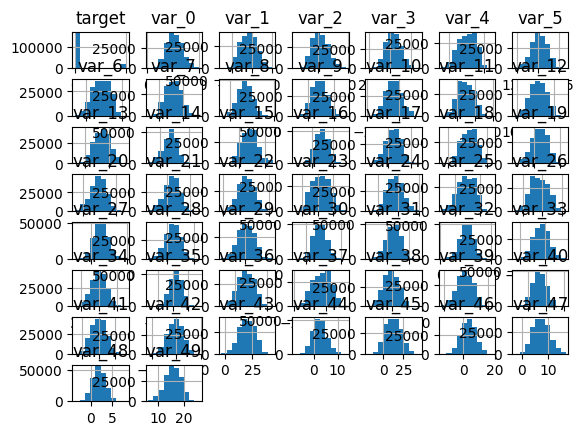

In [71]:
# Display a histogram
df.hist() ;

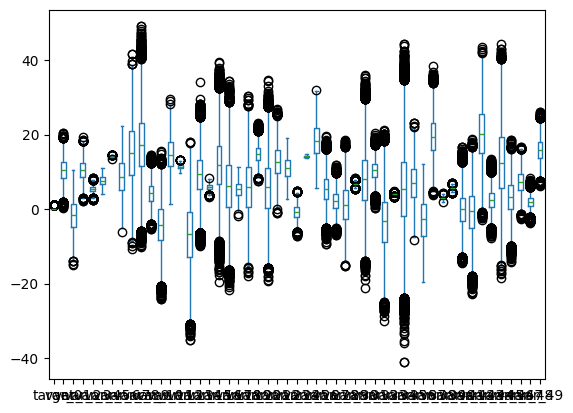

In [72]:
# Display a box and whisker plot
df.plot(kind='box') ;

### Correlation: Independence of Features

In [73]:
# Calculate a correlation matrix
iso_features = df[['target'] + [f'var_{i}' for i in range(50)]]

corr_mat = iso_features.corr()

corr_mat

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
target,1.000000,0.052904,0.049916,0.055450,0.066924,-0.042073,-0.070015,-0.054375,0.044769,-0.057378,...,-0.050049,0.047948,0.041593,-0.061291,0.051110,0.047543,0.056902,0.045506,-0.042765,-0.051718
var_0,0.052904,1.000000,-0.002155,0.006632,0.007155,-0.002247,-0.003147,-0.001717,0.004266,0.000289,...,-0.002602,0.002043,0.001072,-0.001493,0.003662,-0.000227,0.002330,-0.000037,-0.005759,-0.005945
var_1,0.049916,-0.002155,1.000000,0.005644,0.002640,-0.000408,-0.002629,-0.001234,-0.000374,-0.000378,...,-0.003109,0.001891,0.003331,-0.005291,0.000805,0.000387,0.005835,0.003845,-0.003810,-0.005352
var_2,0.055450,0.006632,0.005644,1.000000,0.000679,-0.001293,-0.002718,-0.009171,0.003436,-0.006433,...,-0.004639,0.002059,0.000459,-0.005709,0.001388,0.004021,-0.000657,0.000968,-0.002388,-0.000372
var_3,0.066924,0.007155,0.002640,0.000679,1.000000,-0.006768,-0.002568,-0.005282,0.002685,-0.004835,...,-0.004825,0.002188,-0.000344,-0.005121,-0.000999,0.003463,0.000276,0.005311,-0.001109,-0.002987
var_4,-0.042073,-0.002247,-0.000408,-0.001293,-0.006768,1.000000,0.000845,0.000210,-0.001267,0.000962,...,-0.000824,-0.000685,-0.004266,0.000483,-0.003563,-0.004458,0.000043,-0.000716,0.000190,0.001484
var_5,-0.070015,-0.003147,-0.002629,-0.002718,-0.002568,0.000845,1.000000,0.004778,0.000110,0.005587,...,0.007054,-0.000356,-0.006139,0.004441,-0.005371,-0.002999,0.001721,-0.004525,0.003204,0.008009
var_6,-0.054375,-0.001717,-0.001234,-0.009171,-0.005282,0.000210,0.004778,1.000000,0.001922,0.001879,...,0.001306,-0.001122,-0.001814,0.000897,-0.005164,-0.002714,-0.001001,-0.002799,-0.002182,-0.001663
var_7,0.044769,0.004266,-0.000374,0.003436,0.002685,-0.001267,0.000110,0.001922,1.000000,-0.003654,...,-0.000989,-0.000584,0.002339,0.001428,0.005357,-0.000275,0.002816,0.004656,-0.006991,-0.004983
var_8,-0.057378,0.000289,-0.000378,-0.006433,-0.004835,0.000962,0.005587,0.001879,-0.003654,1.000000,...,0.006917,-0.000172,-0.004523,0.003021,-0.003809,-0.001034,-0.003210,-0.001933,0.000192,0.000810


In [1]:
# Heatmap of the correlation matrix
sns.heatmap(
    corr_mat,
    square=True,
    annot=True,
    fmt='2f',
    cbar=True,
)

plt.xlabel('Features')
plt.xlabel('Features')

NameError: name 'sns' is not defined

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [75]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Processing



### Single Cross Validation ( CV )

#### Two data sets with target and features

In [76]:
# Split data frame into target and features
target_col = 'target'
target = df[ target_col]
features = df.drop(columns=[target_col])

In [77]:
# Display the target
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
179995,0
179996,0
179997,0
179998,0


In [78]:
# Display the features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,22.3368,11.4176,3.6973,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,16.0279,15.7685,3.2069,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,15.2717,7.7995,3.3400,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,20.4504,29.9869,3.7526,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760


#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [79]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets you created in step 10 into training and testing subsets, i.e. train-test split.

In [80]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [81]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(135000, 50)
<class 'pandas.core.frame.DataFrame'>
(45000, 50)
<class 'pandas.core.frame.DataFrame'>
(135000,)
<class 'pandas.core.series.Series'>
(45000,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [82]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [83]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([0, 0, 0, ..., 0, 0, 0])

#### Calculate and report the accuracy.

In [84]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.20888888888888

#### Present a confusion matrix and heatmap

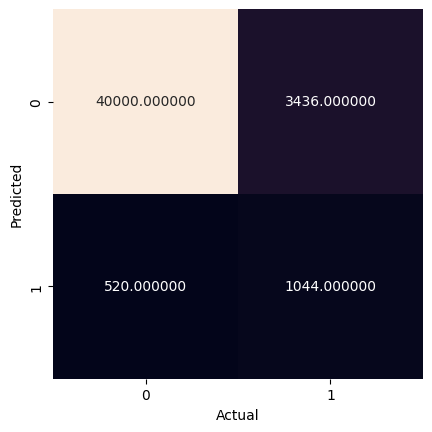

In [85]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Present the results of a Classification Report (sklearn.metrics.classification_report).

In [86]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     40520
           1       0.67      0.23      0.35      4480

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.65     45000
weighted avg       0.90      0.91      0.89     45000



### Multiple Cross-Validation (CV)

In [87]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
   X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
)

# Create an empty GNB model
modelGNB = GaussianNB()

# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

# Make predicitons using the model
pred_results = modelGNB.predict(X_test)

# calculate the accuracy
results[i] = metrics.accuracy_score(y_test, pred_results)

results

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

### Accuracy Comparison

In [88]:
# Compare the accuracies by creating variables for each
acc_single_cv = acc
acc_multi_cv = results[i]

display('Single CV:', acc_single_cv)
display('Multi CV:', acc_multi_cv)

'Single CV:'

0.9120888888888888

'Multi CV:'

np.float64(0.9121777777777778)

### Balance Dataset

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).

Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions.

In [89]:
# Display value counts of the target
df['target'].value_counts()

,count
target,
0,161960
1,18040


In [90]:
# Place minority class in one dataframe
successful_df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
13,1,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,...,5.6656,3.5750,-2.2723,15.7383,8.5618,11.8982,7.4002,7.4031,4.3989,15.6064
29,1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,...,5.4183,8.6643,4.1428,4.7056,4.3694,16.4554,5.9215,7.9676,2.3405,17.4105
63,1,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,...,6.0669,2.5841,2.2445,23.1283,2.9384,27.6213,1.5832,5.0039,3.8814,15.7685
65,1,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,...,6.1149,2.2550,-7.2104,19.7545,6.3190,11.9410,4.6648,6.4227,3.4025,15.1340
71,1,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,...,5.0565,11.9429,0.3140,20.4828,7.9488,11.2587,1.4677,3.5935,2.0013,18.9013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179949,1,8.0020,-0.6347,10.4115,6.6628,7.4319,14.1266,3.2978,23.4884,18.9512,...,5.0568,1.4224,-6.1050,32.4652,6.0889,16.3210,7.9024,10.2831,2.3823,13.7123
179956,1,12.8143,1.7022,12.5143,5.1252,5.9459,14.0384,1.9840,16.6534,21.4191,...,5.5592,6.6583,-3.3179,18.3914,5.4363,12.9044,1.3307,9.1192,0.8223,16.8015
179964,1,10.7885,-2.7318,9.9486,5.4815,5.8853,13.6646,0.6277,12.3875,-0.1087,...,5.0744,0.9305,4.2118,10.3895,6.5844,33.9682,0.9674,8.2839,1.4019,15.1976
179968,1,7.1795,-1.8935,13.6706,4.5245,5.2765,13.9576,8.4353,26.0088,25.4347,...,4.9769,-6.4637,1.2472,27.3877,2.7317,-7.4564,2.5978,9.9902,0.9539,17.1436


In [91]:
# Put majority class into its own dataframe
unsuccessful_df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179995,0,8.9112,-4.4900,11.3795,5.4164,8.3309,14.1869,12.8219,22.3368,11.4176,...,5.9355,5.1764,-5.4817,20.7390,-0.8043,31.3663,8.7194,4.7839,0.9673,14.9529
179996,0,8.2722,7.1923,16.7300,4.9698,5.4907,14.0238,11.9933,16.0279,15.7685,...,5.3550,-1.5556,7.3839,9.9193,5.0860,28.0185,7.4145,4.2814,2.5575,15.3969
179997,0,12.4902,-2.9379,6.5901,4.7242,9.1423,13.9133,12.2314,15.2717,7.7995,...,6.0708,-0.3463,-5.0098,20.4807,5.9814,20.2668,3.1006,3.7701,0.1299,16.1256
179998,0,8.4894,0.7048,11.1518,4.6370,8.1321,14.2921,6.9582,20.4504,29.9869,...,5.5161,3.1774,-4.9374,23.6365,1.0432,29.9365,9.6381,6.9649,2.5546,15.6760


In [92]:
# Create downsample of majority class in another data frame
majority_downsampled = unsuccessful_df.sample(
    n=len(successful_df),
    random_state=42
)

# Display the downsample to verify
print("Minority class:")
print(successful_df['target'].value_counts())

print("Downsampled majority class:")
print(majority_downsampled['target'].value_counts())

Minority class:
target
1    18040
Name: count, dtype: int64
Downsampled majority class:
target
0    18040
Name: count, dtype: int64


In [93]:
# Combine the dataframes
balanced_df = pd.concat([successful_df, majority_downsampled])

# Reset the index
balanced_df = balanced_df.reset_index(drop=True)

In [94]:
# Verify target counts
balanced_df['target'].value_counts()

,count
target,
1,18040
0,18040


#### Backup #3

In [95]:
# Create 3rd backup
df_bak_3 = df.copy()

In [96]:
# Restore from backup
df = df_bak_3.copy()

#### Repeat Multi Cross-Validation

In [48]:
# Split data frame into target and features
target_col = 'target'
target = balanced_df[ target_col]
features = balanced_df.drop(columns=[target_col])

In [46]:
# Display the target
target

,target
0,1
1,1
2,1
3,1
4,1
...,...
36075,0
36076,0
36077,0
36078,0


In [49]:
# Display the features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,1.6565,...,5.6656,3.5750,-2.2723,15.7383,8.5618,11.8982,7.4002,7.4031,4.3989,15.6064
1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,4.3067,...,5.4183,8.6643,4.1428,4.7056,4.3694,16.4554,5.9215,7.9676,2.3405,17.4105
2,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,9.3373,...,6.0669,2.5841,2.2445,23.1283,2.9384,27.6213,1.5832,5.0039,3.8814,15.7685
3,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,3.9192,...,6.1149,2.2550,-7.2104,19.7545,6.3190,11.9410,4.6648,6.4227,3.4025,15.1340
4,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,9.6420,...,5.0565,11.9429,0.3140,20.4828,7.9488,11.2587,1.4677,3.5935,2.0013,18.9013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,12.1422,-2.8988,13.1033,5.3490,6.3190,14.0253,8.7461,6.9149,13.7323,9.6710,...,5.4888,1.9239,-8.6241,31.4515,-0.1695,5.2332,2.8835,11.8437,2.8760,13.9019
36076,9.7524,3.8086,13.1269,4.6394,7.3419,13.8947,4.7452,2.4847,19.7541,8.9868,...,5.5012,2.0163,-5.6715,13.7175,3.0626,8.2874,5.2872,10.1429,3.1365,9.3139
36077,9.9823,-0.4673,9.9985,5.7266,9.3172,13.8065,3.9257,3.6788,12.3129,4.0103,...,6.4015,-5.7487,-11.0315,17.5494,0.2027,6.9605,11.4777,7.8525,-0.5350,17.5503
36078,11.3612,-5.9554,12.0801,5.2457,8.7765,13.8354,3.0177,6.8331,11.9661,6.8629,...,5.2804,0.4139,-9.4331,26.0366,-1.7131,17.7673,-7.2745,4.2469,1.7355,15.0371


In [109]:
# Multiple CV loop
n = 100
balanced_df_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

   # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    balanced_df_results[i] = metrics.accuracy_score(y_test, pred_results)

balanced_df_results

array([0.91204444, 0.90957778, 0.91068889, 0.90855556, 0.91013333,
       0.91144444, 0.91106667, 0.91011111, 0.91235556, 0.91033333,
       0.91053333, 0.91184444, 0.91153333, 0.91184444, 0.91026667,
       0.91186667, 0.9106    , 0.91057778, 0.91064444, 0.91137778,
       0.91151111, 0.9106    , 0.91015556, 0.91042222, 0.91133333,
       0.91053333, 0.90975556, 0.91184444, 0.90962222, 0.91093333,
       0.91237778, 0.91311111, 0.9108    , 0.91115556, 0.91126667,
       0.91231111, 0.91044444, 0.91168889, 0.91228889, 0.9102    ,
       0.91326667, 0.91202222, 0.90944444, 0.91033333, 0.91177778,
       0.91222222, 0.90986667, 0.9112    , 0.91046667, 0.91184444,
       0.90955556, 0.91197778, 0.91004444, 0.91286667, 0.9142    ,
       0.91051111, 0.91011111, 0.91224444, 0.90911111, 0.91051111,
       0.91248889, 0.91231111, 0.90871111, 0.91106667, 0.91237778,
       0.91362222, 0.9116    , 0.91106667, 0.90966667, 0.91006667,
       0.91222222, 0.91148889, 0.91117778, 0.91075556, 0.91155

#### Mean accuracy for balanced dataset

In [110]:
# Report what your mean accuracy for this balanced data set
display(balanced_df_results[i])

np.float64(0.9104666666666666)

#### Histogram of the accuracy scores

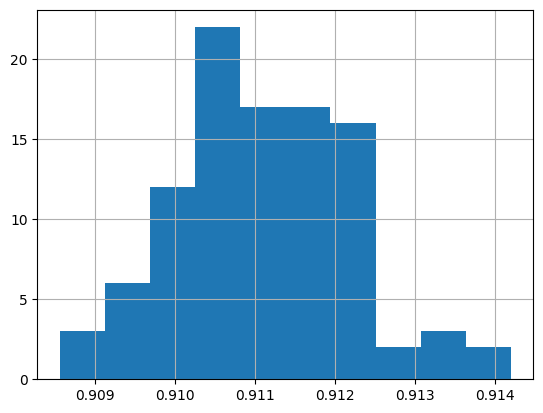

In [111]:
pd.Series(balanced_df_results).hist() ;

What do you notice about the distribution of accuracy scores?

There is a negative skew.

#### Confusion Matrix and Heatmap

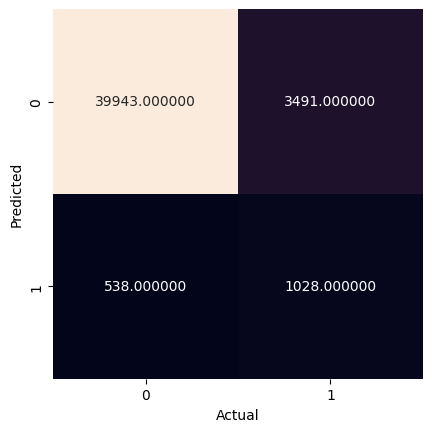

In [112]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "2f",
    cbar = False,
)
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Classification Report

In [113]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     40481
           1       0.66      0.23      0.34      4519

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.64     45000
weighted avg       0.89      0.91      0.89     45000



What do you notice? That is, how do the different metrics compare to each other?

## Data Visualization/Communication of Results


### Data Visualization

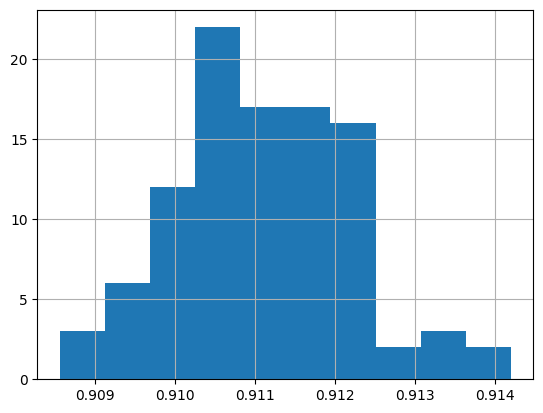

In [114]:
# Display a histagram of the results
pd.Series(balanced_df_results).hist() ;

### Conclusion

- Using all var columns and balancing the dataset gave us 91% accuracy, same as with previous Pass-05
- Bad at predicting no-transactions
- OK at predicting a successful transaction
- Low false positive (we predict customer will make a transaction but customer does not)
- High false negative (we predict customer will not make a transaction but customer does)

### Future work


- For Pass-07,
  - Use big dataset
  - Use only the first 15 columns
  - Use ony the first 10,000 rows